In [1]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

%matplotlib widget

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 150,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# # ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=8)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()




In [2]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
from pathlib import Path
import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

%matplotlib widget

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd
from tqdm.auto import tqdm 

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc


import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import importlib
%load_ext autoreload
%autoreload 2

import roboarmanalysis as ra
from tqdm.auto import tqdm
from contextlib import contextmanager


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 50,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=8)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()



import re
from math import inf
from typing import Iterable

# Variant order for sorting (unknowns last)
_VARIANT_ORDER = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4}

def assign_conditions(m) -> None:
    """
    Parse m's path/filename and write:
      m.stator_variant ∈ {'A','B','C','D','E'} (or None)
      m.bias_voltage_V : float (or None)
      m.time_halfcycle_s : float seconds (or None)
      m.source_path : str (best-guess source path/filename)
      m._detect_notes : str (human-readable summary)
    Side effects only. Returns None.

    All helpers are defined locally to keep the API surface minimal.
    """

    # -------- helpers (local only) --------
    def _path_of(obj) -> str:
        for a in ("path","filepath","file","filename","source","source_file",
                  "hdf5_path","hdf5","directory","dirpath"):
            v = getattr(obj, a, None)
            if isinstance(v, str) and v:
                return v
        for a in ("meta","info","attrs","props"):
            d = getattr(obj, a, None)
            if isinstance(d, dict):
                for k in ("path","filepath","file","filename","source","source_file",
                          "hdf5_path","hdf5","directory","dirpath"):
                    v = d.get(k)
                    if isinstance(v, str) and v:
                        return v
        return str(obj)

    # Precedence: more specific first; restricted to A..E as requested
    _VARIANT_RULES = [
        (re.compile(r'[/\\]ratchet2_eds([/\\]|_|$)', re.I), 'F'),  # map EDS → E (change if you need 'F')
        (re.compile(r'[/\\]ratchet2_e([/\\]|_|$)',   re.I), 'C'),
        (re.compile(r'[/\\]ratchet2_8ds([/\\]|_|$)', re.I), 'E'),
        (re.compile(r'[/\\]ratchet2_8([/\\]|_|$)',   re.I), 'D'),
        (re.compile(r'[/\\]ratchet2_0([/\\]|_|$)',   re.I), 'B'),
        (re.compile(r'[/\\]ratchet1_0([/\\]|_|$)',   re.I), 'A'),
    ]
    def _detect_variant(s: str):
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(s):
                return lab
        # defensive second pass with separators flattened
        snk = s.replace('\\', '_').replace('/', '_')
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(snk):
                return lab
        return None

    # -------- /helpers --------

    s = _path_of(m)
    notes = []

    v = _detect_variant(s)
    try: setattr(m, "stator_variant", v)
    except Exception: notes.append("warn: cannot set stator_variant")
    notes.append(f"variant: {v}" if v else "variant: not found")


    try: setattr(m, "source_path", s)
    except Exception: pass
    try: setattr(m, "_detect_notes", "; ".join(notes))
    except Exception: pass


def reorder_by_variant(m_list: Iterable, annotate: bool = True):
    """
    Return a NEW list ordered by:
      1) stator_variant (A<B<C<D<E<Unknown),
      2) bias_voltage_V ascending (unknowns last),
      3) time_halfcycle_s ascending (unknowns last),
      4) original index (stable).
    If annotate=True, runs assign_conditions(m) for each m first.
    """
    packed = []
    for i, m in enumerate(m_list):
        if annotate:
            assign_conditions(m)

        v = getattr(m, "stator_variant", None)
        vkey = _VARIANT_ORDER.get(v, 10**6)

        packed.append((vkey, i, m))

    packed.sort(key=lambda t: (t[0], t[1]))
    return [t[-1] for t in packed]




def purge_locscolumns(m, cols=None):
    LOC_COLUMNS_TO_DROP = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']    
    if cols is None:
        cols = LOC_COLUMNS_TO_DROP
    if hasattr(m, 'locs') and isinstance(m.locs, pd.DataFrame):
        drop = [c for c in cols if c in m.locs.columns]
        if drop:
            m.locs = m.locs.drop(columns=drop)



# -------- optional vik colormap (fallback to coolwarm) --------
try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")
    cmc = None

# -------- style --------
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 180,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _style_ax(ax, grey="0.25"):
    for s in ax.spines.values():
        s.set_color(grey); s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey); ax.yaxis.label.set_color(grey)
    ax.title.set_color(grey); ax.grid(False)


import matplotlib as mpl
mpl.rcParams["figure.dpi"] = 100
mpl.rcParams["savefig.dpi"] = 300


### Load and trim dataset

In [3]:
save_dir = Path(r"N:\users\lweiss\_06_Umbrella_Sampling\01_Dataset\260707_L2ss")
keywords = ["fov01"]

exclude_keywords = []

m_list_loaded = ra.load_multiple_measurements(
    save_dir,
    keywords=keywords,
    exclude_keywords=exclude_keywords,
)



 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in N:\users\lweiss\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to_your_txt_file)
Adding file: N:\users\lweiss\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1\260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5

 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in N:\users\lweiss\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file 

In [4]:
m_list = m_list_loaded

for m in m_list:
    if "UMB" in Path(m.path).name:
        m.get_flat_particles = types.MethodType(_get_flat_particles, m)

### Process dataset - assign phases, compute polar coordinates, trajectories

In [5]:
# Assign phases, convert to polar coordinates, compute trajectories
columns_to_drop = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']
allowed_missed_percentage = 20
dt_s = 0.005  # 5 ms acquisition


for idx, m in enumerate(m_list):
    if "UMB" in Path(m.path).name:
        m.protocol = {}
        m.protocol["diff"] = (0, 1)
        for i, deg in enumerate(range(0, 360, 20)):
            start = 5 * i+1
            m.protocol[f"deg-{deg}"] = (start, start + 5)
    
        m.protocol["umbrella"] = (1, 91)
        m.protocol["all"] = (0, 91)
    
    elif "DIFF" in Path(m.path).name:
        m.protocol = {"diff": (0, 180)}
        m.protocol["all"] = (0, 180)

    m._has_protocol = True
    m._num_phases = len(m.protocol)

ra.fit_circles_with_reference_measurement(m_list, m_list, particles=None)


for idx, m in enumerate(m_list):
    if hasattr(m, "protocol") and "all" in m.protocol:
        t0, t1 = m.protocol["all"]
        duration_s = t1 - t0
    else:
        duration_s = (m.locs["frame"].max() - m.locs["frame"].min() + 1) * dt_s

    expected_frames = duration_s / dt_s
    frame_threshold = (1 - allowed_missed_percentage / 100) * expected_frames


    counts = m.locs.groupby("group")["frame"].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)
    purge_locscolumns(m, cols = columns_to_drop)
    
    print(str(idx) + ': ' + Path(m.path).name + ' ' + str(len(m.whitelist)) + ' particles.')



for idx, m in enumerate(m_list):
    # m.fit_circles()
    # m.polar_coordinates()
    m.calc_trajectories()


Fitting circles for whitelist:


  0%|          | 0/241 [00:00<?, ?it/s]

Compute polar coordinates for all measurements.
0: 260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 217 particles.
1: 260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 215 particles.
2: 260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_render_picked.hdf5 0 particles.


Phases:   0%|          | 0/21 [00:00<?, ?it/s]

  diff:   0%|          | 0/217 [00:00<?, ?it/s]

  deg-0:   0%|          | 0/217 [00:00<?, ?it/s]

... (42 outputs left out)

[WARN] Phase 'diff': no localizations found for any particle in frames [0..0].


  diff: 0it [00:00, ?it/s]

[WARN] Phase 'all': no localizations found for any particle in frames [0..0].


  all: 0it [00:00, ?it/s]

### Prepare Figure 2b - exemplary localization scatter plot and histograms

In [6]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from pathlib import Path
# from matplotlib.gridspec import GridSpec


# def ck_colors():
#     return {
#         "orange":     (215/255, 131/255,  41/255),
#         "palecyan":   (167/255, 197/255, 197/255),
#         "darkcyan":   (105/255, 155/255, 155/255),
#         "grey":       (0.25, 0.25, 0.25),
#         "lightgrey":  (0.72, 0.72, 0.72),
#     }


# def mm_to_inch(mm):
#     return mm / 25.4


# def phase_bounds(m, phase):
#     value = m.protocol[phase]
#     while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple)):
#         value = value[0]
#     if isinstance(value, dict):
#         return float(value.get("start", value.get("t0"))), float(value.get("end", value.get("t1")))
#     return float(value[0]), float(value[1])


# def ensure_time_column(m, dt_s=0.005):
#     if "t" not in m.locs.columns:
#         if "averagetime" in m.locs.columns:
#             m.locs["t"] = m.locs["averagetime"]
#         elif hasattr(m, "_average_tpf"):
#             m.locs["t"] = m.locs["frame"] * float(m._average_tpf)
#         else:
#             m.locs["t"] = m.locs["frame"] * dt_s


# def get_phase_locs(m, particle, phase, dt_s=0.005):
#     ensure_time_column(m, dt_s=dt_s)
#     t0, t1 = phase_bounds(m, phase)
#     return m.locs[
#         (m.locs["group"].astype(int) == int(particle))
#         & (m.locs["t"] >= t0)
#         & (m.locs["t"] < t1)
#     ].copy()


# def get_particle_center_radius(m, particle):
#     xc, yc, R = np.nan, np.nan, np.nan

#     if not hasattr(m, "particle_data"):
#         return xc, yc, R

#     pdata = m.particle_data

#     try:
#         d = pdata[int(particle)]
#         if isinstance(d, dict):
#             xc = d.get("xc", d.get("x_c", d.get("center_x", np.nan)))
#             yc = d.get("yc", d.get("y_c", d.get("center_y", np.nan)))
#             R = d.get("R", d.get("r", d.get("radius", np.nan)))
#     except Exception:
#         pass

#     try:
#         row = pdata.loc[int(particle)]
#         for key in ["xc", "x_c", "center_x"]:
#             if key in row.index:
#                 xc = row[key]
#         for key in ["yc", "y_c", "center_y"]:
#             if key in row.index:
#                 yc = row[key]
#         for key in ["R", "r", "radius"]:
#             if key in row.index:
#                 R = row[key]
#     except Exception:
#         pass

#     return float(xc), float(yc), float(R)


# def get_angle_column(df, m=None, particle=None):
#     for col in ["phi", "theta", "angle", "angle_rad"]:
#         if col in df.columns:
#             return np.asarray(df[col], dtype=float)

#     xc, yc, _ = get_particle_center_radius(m, particle)
#     return np.arctan2(df["y"].to_numpy() - yc, df["x"].to_numpy() - xc)


# def wrap_pi(phi):
#     return (phi + np.pi) % (2 * np.pi) - np.pi


# def angle_diff(phi, mu):
#     return np.angle(np.exp(1j * (phi - mu)))


# def density_hist(phi, bins):
#     phi = wrap_pi(np.asarray(phi, dtype=float))
#     phi = phi[np.isfinite(phi)]
#     centers = 0.5 * (bins[:-1] + bins[1:])
#     if len(phi) == 0:
#         return centers, np.zeros_like(centers)
#     h, _ = np.histogram(phi, bins=bins, density=True)
#     return centers, h


# def fit_angular_gaussian(phi):
#     phi = wrap_pi(np.asarray(phi, dtype=float))
#     phi = phi[np.isfinite(phi)]

#     if len(phi) < 5:
#         return np.nan, np.nan, np.nan

#     mu = np.angle(np.mean(np.exp(1j * phi)))
#     dphi = angle_diff(phi, mu)
#     sigma = np.std(dphi, ddof=1)

#     if not np.isfinite(sigma) or sigma <= 0:
#         return mu, np.nan, np.nan

#     kappa = 1 / sigma**2
#     return mu, sigma, kappa


# def gaussian_periodic_axis(x, mu, sigma):
#     if not np.isfinite(mu) or not np.isfinite(sigma) or sigma <= 0:
#         return np.full_like(x, np.nan)
#     d = angle_diff(x, mu)
#     return np.exp(-0.5 * (d / sigma)**2) / (np.sqrt(2 * np.pi) * sigma)


# def plot_circle(ax, xc, yc, R, color, lw=0.7, alpha=0.7):
#     if not (np.isfinite(xc) and np.isfinite(yc) and np.isfinite(R)):
#         return
#     t = np.linspace(0, 2 * np.pi, 600)
#     ax.plot(xc + R * np.cos(t), yc + R * np.sin(t), color=color, lw=lw, alpha=alpha, zorder=5)


# def plot_center_dot(ax, xc, yc, size=8, color=(0.25, 0.25, 0.25)):
#     if np.isfinite(xc) and np.isfinite(yc):
#         ax.scatter([xc], [yc], s=size, color=color, linewidths=0, zorder=7)


# def add_scalebar(ax, px_per_nm, length_nm=200, fontsize=7, lw=1.5, pad_frac=0.08):
#     length_px = length_nm * px_per_nm

#     x0, x1 = ax.get_xlim()
#     y0, y1 = ax.get_ylim()
#     dx = x1 - x0
#     dy = y1 - y0

#     xb = x0 + pad_frac * dx
#     yb = y0 + pad_frac * dy

#     ax.plot([xb, xb + length_px], [yb, yb], color="black", lw=lw, solid_capstyle="butt", zorder=10)
#     ax.text(xb, yb + 0.035 * dy, f"{length_nm:g} nm", ha="left", va="bottom", fontsize=fontsize)


# def plot_raw_diff_vs_bias_panel_b(
#     m_list,
#     study_particle,
#     reference_particle,
#     diff_phase="diff",
#     bias_phase="deg-0",
#     m_diff=None,
#     m_umb=None,
#     dt_s=0.005,
#     width_mm=95,
#     height_mm=72,
#     fontsize=7,
#     px_per_nm=1.0,
#     scalebar_nm=200,
#     nbins=36,
#     diff_marker_size=1.4,
#     bias_marker_size=1.9,
#     diff_alpha=0.20,
#     bias_alpha=0.82,
#     circle_lw=0.70,
#     scatter_box_px=None,
#     fixed_scatter_box=True,
#     fit_gaussian_for="both",
#     rasterize_locs=True,
# ):
#     C = ck_colors()

#     if m_diff is None:
#         m_diff = [
#             m for m in m_list
#             if ("DIFF" in Path(m.path).name.upper()) and ("UMB" not in Path(m.path).name.upper())
#         ][0]

#     if m_umb is None:
#         m_umb = [m for m in m_list if "UMB" in Path(m.path).name.upper()][0]

#     particles = [
#         {"role": "study", "particle": int(study_particle), "color": C["darkcyan"]},
#         {"role": "reference", "particle": int(reference_particle), "color": C["orange"]},
#     ]

#     bins = np.linspace(-np.pi, np.pi, nbins + 1)
#     fig = plt.figure(figsize=(mm_to_inch(width_mm), mm_to_inch(height_mm)))

#     gs = GridSpec(
#         2, 2,
#         figure=fig,
#         height_ratios=[1.0, 0.78],
#         width_ratios=[1.0, 1.0],
#         left=0.10,
#         right=0.985,
#         bottom=0.16,
#         top=0.97,
#         wspace=0.28,
#         hspace=0.34,
#     )

#     data = []
#     hist_ylim_max = 0
#     global_span = 0

#     for entry in particles:
#         p = entry["particle"]

#         diff_locs = get_phase_locs(m_diff, p, diff_phase, dt_s=dt_s)
#         bias_locs = get_phase_locs(m_umb, p, bias_phase, dt_s=dt_s)

#         phi_diff = get_angle_column(diff_locs, m=m_diff, particle=p) if len(diff_locs) else np.array([])
#         phi_bias = get_angle_column(bias_locs, m=m_umb, particle=p) if len(bias_locs) else np.array([])

#         centers, h_diff = density_hist(phi_diff, bins)
#         _, h_bias = density_hist(phi_bias, bins)

#         mu, sigma, kappa = fit_angular_gaussian(phi_bias)
#         xfit = np.linspace(-np.pi, np.pi, 900)
#         yfit = gaussian_periodic_axis(xfit, mu, sigma)

#         xc, yc, R = get_particle_center_radius(m_diff, p)

#         xy_parts = []
#         if len(diff_locs):
#             xy_parts.append(diff_locs[["x", "y"]])
#         if len(bias_locs):
#             xy_parts.append(bias_locs[["x", "y"]])

#         if len(xy_parts):
#             xy_all = pd.concat(xy_parts, ignore_index=True)
#             local_span = max(
#                 xy_all["x"].max() - xy_all["x"].min(),
#                 xy_all["y"].max() - xy_all["y"].min(),
#                 2.3 * R if np.isfinite(R) else 1,
#                 scalebar_nm * px_per_nm * 2.0,
#             )
#             global_span = max(global_span, local_span * 1.12)

#         hist_ylim_max = max(
#             hist_ylim_max,
#             np.nanmax(h_diff) if len(h_diff) else 0,
#             np.nanmax(h_bias) if len(h_bias) else 0,
#             np.nanmax(yfit) if np.isfinite(yfit).any() else 0,
#         )

#         data.append({
#             **entry,
#             "diff_locs": diff_locs,
#             "bias_locs": bias_locs,
#             "phi_diff": phi_diff,
#             "phi_bias": phi_bias,
#             "centers": centers,
#             "h_diff": h_diff,
#             "h_bias": h_bias,
#             "mu": mu,
#             "sigma": sigma,
#             "kappa": kappa,
#             "xfit": xfit,
#             "yfit": yfit,
#             "xc": xc,
#             "yc": yc,
#             "R": R,
#         })

#     if scatter_box_px is None:
#         scatter_box_px = global_span if fixed_scatter_box else None

#     axes_xy = []
#     axes_hist = []

#     for col, D in enumerate(data):
#         ax_xy = fig.add_subplot(gs[0, col])
#         ax_hist = fig.add_subplot(gs[1, col])

#         axes_xy.append(ax_xy)
#         axes_hist.append(ax_hist)

#         color = D["color"]

#         if len(D["diff_locs"]):
#             ax_xy.scatter(
#                 D["diff_locs"]["x"],
#                 D["diff_locs"]["y"],
#                 s=diff_marker_size,
#                 color=C["lightgrey"],
#                 alpha=diff_alpha,
#                 linewidths=0,
#                 rasterized=rasterize_locs,
#                 zorder=1,
#             )

#         if len(D["bias_locs"]):
#             ax_xy.scatter(
#                 D["bias_locs"]["x"],
#                 D["bias_locs"]["y"],
#                 s=bias_marker_size,
#                 color=color,
#                 alpha=bias_alpha,
#                 linewidths=0,
#                 rasterized=rasterize_locs,
#                 zorder=2,
#             )

#         plot_circle(ax_xy, D["xc"], D["yc"], D["R"], color=C["grey"], lw=circle_lw, alpha=0.65)
#         plot_center_dot(ax_xy, D["xc"], D["yc"], size=8, color=C["grey"])

#         if np.isfinite(D["xc"]) and np.isfinite(D["yc"]):
#             xmid, ymid = D["xc"], D["yc"]
#         elif len(D["diff_locs"]):
#             xmid, ymid = D["diff_locs"]["x"].mean(), D["diff_locs"]["y"].mean()
#         else:
#             xmid, ymid = 0, 0

#         span = scatter_box_px
#         ax_xy.set_xlim(xmid - span / 2, xmid + span / 2)
#         ax_xy.set_ylim(ymid - span / 2, ymid + span / 2)

#         ax_xy.set_aspect("equal", adjustable="box")
#         ax_xy.set_box_aspect(1)
#         ax_xy.set_xticks([])
#         ax_xy.set_yticks([])
#         ax_xy.set_xlabel("")
#         ax_xy.set_ylabel("")
#         ax_xy.set_title("")

#         for spine in ax_xy.spines.values():
#             spine.set_linewidth(0.55)
#             spine.set_color("black")

#         add_scalebar(
#             ax_xy,
#             px_per_nm=px_per_nm,
#             length_nm=scalebar_nm,
#             fontsize=fontsize,
#             lw=1.5,
#         )

#         ax_hist.fill_between(D["centers"], D["h_diff"], step="mid", color=C["grey"], alpha=0.16, linewidth=0)
#         ax_hist.plot(D["centers"], D["h_diff"], color=C["grey"], lw=0.90, alpha=0.85)

#         ax_hist.fill_between(D["centers"], D["h_bias"], step="mid", color=color, alpha=0.28, linewidth=0)
#         ax_hist.plot(D["centers"], D["h_bias"], color=color, lw=1.20, alpha=0.95)

#         do_fit = (
#             fit_gaussian_for == "both"
#             or (fit_gaussian_for == "reference" and D["role"] == "reference")
#             or (fit_gaussian_for == "study" and D["role"] == "study")
#         )

#         if do_fit and np.isfinite(D["yfit"]).any():
#             ax_hist.plot(D["xfit"], D["yfit"], color=color, lw=1.15, ls="--", alpha=0.95)

#             if np.isfinite(D["kappa"]):
#                 ax_hist.text(
#                     0.04,
#                     0.92,
#                     f"κtrap = {D['kappa']:.1f} kBT rad⁻²",
#                     transform=ax_hist.transAxes,
#                     ha="left",
#                     va="top",
#                     fontsize=fontsize,
#                     color=color,
#                 )

#         ax_hist.set_xlim(-np.pi, np.pi)
#         ax_hist.set_ylim(0, hist_ylim_max * 1.08 if hist_ylim_max > 0 else 1)

#         ax_hist.set_xticks([-np.pi, 0, np.pi])
#         ax_hist.set_xticklabels(["−π", "0", "π"], fontsize=fontsize)
#         ax_hist.set_xlabel("φ / rad", fontsize=fontsize)

#         ax_hist.set_yticks([])
#         ax_hist.set_ylabel("")

#         ax_hist.tick_params(axis="x", labelsize=fontsize, length=2.0, width=0.55)
#         ax_hist.tick_params(axis="y", length=0, width=0)

#         ax_hist.spines["top"].set_visible(False)
#         ax_hist.spines["right"].set_visible(False)

#         for spine in ["left", "bottom"]:
#             ax_hist.spines[spine].set_linewidth(0.55)

#     for ax_xy, ax_hist in zip(axes_xy, axes_hist):
#         pos_xy = ax_xy.get_position()
#         pos_hist = ax_hist.get_position()
#         ax_hist.set_position([pos_xy.x0, pos_hist.y0, pos_xy.width, pos_hist.height])

#     return fig, {"xy": axes_xy, "hist": axes_hist, "data": data}


# def save_figure_svg_png(fig, directory, name, dpi=300, transparent=True, bbox_inches="tight"):
#     directory = Path(directory)
#     directory.mkdir(parents=True, exist_ok=True)

#     name = Path(name).stem

#     svg_path = directory / f"{name}.svg"
#     png_path = directory / f"{name}.png"

#     fig.savefig(svg_path, dpi=dpi, transparent=transparent, bbox_inches=bbox_inches)
#     fig.savefig(png_path, dpi=dpi, transparent=transparent, bbox_inches=bbox_inches)

#     return svg_path, png_path


# fig_b, axdict_b = plot_raw_diff_vs_bias_panel_b(
#     m_list=m_list,
#     study_particle=16,
#     reference_particle=126,
#     diff_phase="diff",
#     bias_phase="deg-20",

#     width_mm=95,
#     height_mm=72,
#     fontsize=7,

#     dt_s=0.005,
#     px_per_nm=1.0,
#     scalebar_nm=200,

#     nbins=36,

#     diff_marker_size=1.4,
#     bias_marker_size=1.9,
#     diff_alpha=0.20,
#     bias_alpha=0.82,

#     fixed_scatter_box=True,
#     scatter_box_px=None,

#     fit_gaussian_for="both",
#     rasterize_locs=True,
# )

# plt.show()

# svg_path, png_path = save_figure_svg_png(
#     fig=fig_b,
#     directory=r"R:\_06_Umbrella_Sampling\02_Figures\Figure_2",
#     name="Fig2_locs_rotorunderstudy_reference",
# )

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.gridspec import GridSpec


def ck_colors():
    return {
        "orange":     (215/255, 131/255,  41/255),
        "beige":      (225/255, 209/255, 180/255),
        "gold":       (226/255, 172/255,  72/255),
        "olive":      (140/255, 135/255,  59/255),
        "offwhite":   (222/255, 224/255, 213/255),
        "palecyan":   (167/255, 197/255, 197/255),
        "darkcyan":   (105/255, 155/255, 155/255),
        "lightblue":  ( 73/255, 139/255, 167/255),
        "darkblue":   ( 46/255,  89/255, 108/255),
        "darkred":    (102/255,  27/255,  35/255),
        "grey":       (0.25, 0.25, 0.25),
        "lightgrey":  (0.72, 0.72, 0.72),

        # Figure 2 rotor colors
        "target_teal":     (111/255, 166/255, 166/255),  # #6FA6A6
        "calib_warmgold":  (198/255, 161/255,  91/255),  # #C6A15B
        "free_grey":      (201/255, 201/255, 201/255),  # #C9C9C9
        "fit_darkgrey":   ( 46/255,  46/255,  46/255),  # #2E2E2E
    }

def mm_to_inch(mm):
    return mm / 25.4


def phase_bounds(m, phase):
    value = m.protocol[phase]
    while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple)):
        value = value[0]
    if isinstance(value, dict):
        return float(value.get("start", value.get("t0"))), float(value.get("end", value.get("t1")))
    return float(value[0]), float(value[1])


def ensure_time_column(m, dt_s=0.005):
    if "t" not in m.locs.columns:
        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"]
        elif hasattr(m, "_average_tpf"):
            m.locs["t"] = m.locs["frame"] * float(m._average_tpf)
        else:
            m.locs["t"] = m.locs["frame"] * dt_s


def get_phase_locs(m, particle, phase, dt_s=0.005):
    ensure_time_column(m, dt_s=dt_s)
    t0, t1 = phase_bounds(m, phase)
    return m.locs[
        (m.locs["group"].astype(int) == int(particle))
        & (m.locs["t"] >= t0)
        & (m.locs["t"] < t1)
    ].copy()


def get_particle_center_radius(m, particle):
    xc, yc, R = np.nan, np.nan, np.nan

    if not hasattr(m, "particle_data"):
        return xc, yc, R

    pdata = m.particle_data

    try:
        d = pdata[int(particle)]
        if isinstance(d, dict):
            xc = d.get("xc", d.get("x_c", d.get("center_x", np.nan)))
            yc = d.get("yc", d.get("y_c", d.get("center_y", np.nan)))
            R = d.get("R", d.get("r", d.get("radius", np.nan)))
    except Exception:
        pass

    try:
        row = pdata.loc[int(particle)]
        for key in ["xc", "x_c", "center_x"]:
            if key in row.index:
                xc = row[key]
        for key in ["yc", "y_c", "center_y"]:
            if key in row.index:
                yc = row[key]
        for key in ["R", "r", "radius"]:
            if key in row.index:
                R = row[key]
    except Exception:
        pass

    return float(xc), float(yc), float(R)


def get_angle_column(df, m=None, particle=None):
    for col in ["phi", "theta", "angle", "angle_rad"]:
        if col in df.columns:
            return np.asarray(df[col], dtype=float)

    xc, yc, _ = get_particle_center_radius(m, particle)
    return np.arctan2(df["y"].to_numpy() - yc, df["x"].to_numpy() - xc)


def wrap_pi(phi):
    return (phi + np.pi) % (2 * np.pi) - np.pi


def angle_diff(phi, mu):
    return np.angle(np.exp(1j * (phi - mu)))


def density_hist(phi, bins):
    phi = wrap_pi(np.asarray(phi, dtype=float))
    phi = phi[np.isfinite(phi)]
    centers = 0.5 * (bins[:-1] + bins[1:])
    if len(phi) == 0:
        return centers, np.zeros_like(centers)
    h, _ = np.histogram(phi, bins=bins, density=True)
    return centers, h


def fit_angular_gaussian(phi):
    phi = wrap_pi(np.asarray(phi, dtype=float))
    phi = phi[np.isfinite(phi)]

    if len(phi) < 5:
        return np.nan, np.nan, np.nan

    mu = np.angle(np.mean(np.exp(1j * phi)))
    dphi = angle_diff(phi, mu)
    sigma = np.std(dphi, ddof=1)

    if not np.isfinite(sigma) or sigma <= 0:
        return mu, np.nan, np.nan

    kappa = 1 / sigma**2
    return mu, sigma, kappa


def gaussian_periodic_axis(x, mu, sigma):
    if not np.isfinite(mu) or not np.isfinite(sigma) or sigma <= 0:
        return np.full_like(x, np.nan)
    d = angle_diff(x, mu)
    return np.exp(-0.5 * (d / sigma)**2) / (np.sqrt(2 * np.pi) * sigma)


def plot_circle(ax, xc, yc, R, color, lw=0.7, alpha=0.7):
    if not (np.isfinite(xc) and np.isfinite(yc) and np.isfinite(R)):
        return
    t = np.linspace(0, 2 * np.pi, 600)
    ax.plot(xc + R * np.cos(t), yc + R * np.sin(t), color=color, lw=lw, alpha=alpha, zorder=5)


def plot_center_dot(ax, xc, yc, size=8, color=(0.25, 0.25, 0.25)):
    if np.isfinite(xc) and np.isfinite(yc):
        ax.scatter([xc], [yc], s=size, color=color, linewidths=0, zorder=7)


def add_scalebar(ax, px_per_nm, length_nm=200, fontsize=7, lw=1.5, pad_frac=0.08):
    length_px = length_nm * px_per_nm

    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    dx = x1 - x0
    dy = y1 - y0

    xb = x0 + pad_frac * dx
    yb = y0 + pad_frac * dy

    ax.plot([xb, xb + length_px], [yb, yb], color="black", lw=lw, solid_capstyle="butt", zorder=10)
    ax.text(xb, yb + 0.035 * dy, f"{length_nm:g} nm", ha="left", va="bottom", fontsize=fontsize)


def plot_raw_diff_vs_bias_panel_b(
    m_list,
    study_particle,
    reference_particle,
    diff_phase="diff",
    bias_phase="deg-0",
    m_diff=None,
    m_umb=None,
    dt_s=0.005,
    width_mm=95,
    height_mm=72,
    fontsize=7,
    px_per_nm=1.0,
    scalebar_nm=200,
    nbins=36,
    diff_marker_size=1.4,
    bias_marker_size=1.9,
    diff_alpha=0.20,
    bias_alpha=0.82,
    circle_lw=0.70,
    scatter_box_px=None,
    fixed_scatter_box=True,
    fit_gaussian_for="both",
    rasterize_locs=True,
):
    C = ck_colors()

    if m_diff is None:
        m_diff = [
            m for m in m_list
            if ("DIFF" in Path(m.path).name.upper()) and ("UMB" not in Path(m.path).name.upper())
        ][0]

    if m_umb is None:
        m_umb = [m for m in m_list if "UMB" in Path(m.path).name.upper()][0]

    particles = [
        {"role": "study", "particle": int(study_particle), "color": C["darkcyan"]},
        {"role": "reference", "particle": int(reference_particle), "color": C["calib_warmgold"]},
    ]

    bins = np.linspace(-np.pi, np.pi, nbins + 1)
    fig = plt.figure(figsize=(mm_to_inch(width_mm), mm_to_inch(height_mm)))

    gs = GridSpec(
        2, 2,
        figure=fig,
        height_ratios=[1.0, 0.78],
        width_ratios=[1.0, 1.0],
        left=0.10,
        right=0.985,
        bottom=0.16,
        top=0.97,
        wspace=0.28,
        hspace=0.34,
    )

    data = []
    hist_ylim_max = 0
    global_span = 0

    for entry in particles:
        p = entry["particle"]

        diff_locs = get_phase_locs(m_diff, p, diff_phase, dt_s=dt_s)
        bias_locs = get_phase_locs(m_umb, p, bias_phase, dt_s=dt_s)

        phi_diff = get_angle_column(diff_locs, m=m_diff, particle=p) if len(diff_locs) else np.array([])
        phi_bias = get_angle_column(bias_locs, m=m_umb, particle=p) if len(bias_locs) else np.array([])

        centers, h_diff = density_hist(phi_diff, bins)
        _, h_bias = density_hist(phi_bias, bins)

        mu, sigma, kappa = fit_angular_gaussian(phi_bias)
        xfit = np.linspace(-np.pi, np.pi, 900)
        yfit = gaussian_periodic_axis(xfit, mu, sigma)

        xc, yc, R = get_particle_center_radius(m_diff, p)

        xy_parts = []
        if len(diff_locs):
            xy_parts.append(diff_locs[["x", "y"]])
        if len(bias_locs):
            xy_parts.append(bias_locs[["x", "y"]])

        if len(xy_parts):
            xy_all = pd.concat(xy_parts, ignore_index=True)
            local_span = max(
                xy_all["x"].max() - xy_all["x"].min(),
                xy_all["y"].max() - xy_all["y"].min(),
                2.3 * R if np.isfinite(R) else 1,
                scalebar_nm * px_per_nm * 2.0,
            )
            global_span = max(global_span, local_span * 1.12)

        hist_ylim_max = max(
            hist_ylim_max,
            np.nanmax(h_diff) if len(h_diff) else 0,
            np.nanmax(h_bias) if len(h_bias) else 0,
            np.nanmax(yfit) if np.isfinite(yfit).any() else 0,
        )

        data.append({
            **entry,
            "diff_locs": diff_locs,
            "bias_locs": bias_locs,
            "phi_diff": phi_diff,
            "phi_bias": phi_bias,
            "centers": centers,
            "h_diff": h_diff,
            "h_bias": h_bias,
            "mu": mu,
            "sigma": sigma,
            "kappa": kappa,
            "xfit": xfit,
            "yfit": yfit,
            "xc": xc,
            "yc": yc,
            "R": R,
        })

    if scatter_box_px is None:
        scatter_box_px = global_span if fixed_scatter_box else None

    axes_xy = []
    axes_hist = []

    for col, D in enumerate(data):
        ax_xy = fig.add_subplot(gs[0, col])
        ax_hist = fig.add_subplot(gs[1, col])

        axes_xy.append(ax_xy)
        axes_hist.append(ax_hist)

        color = D["color"]

        if len(D["diff_locs"]):
            ax_xy.scatter(
                D["diff_locs"]["x"],
                D["diff_locs"]["y"],
                s=diff_marker_size,
                color=C["lightgrey"],
                alpha=diff_alpha,
                linewidths=0,
                rasterized=rasterize_locs,
                zorder=1,
            )

        if len(D["bias_locs"]):
            ax_xy.scatter(
                D["bias_locs"]["x"],
                D["bias_locs"]["y"],
                s=bias_marker_size,
                color=color,
                alpha=bias_alpha,
                linewidths=0,
                rasterized=rasterize_locs,
                zorder=2,
            )

        plot_circle(ax_xy, D["xc"], D["yc"], D["R"], color=C["grey"], lw=circle_lw, alpha=0.65)
        plot_center_dot(ax_xy, D["xc"], D["yc"], size=8, color=C["grey"])

        if np.isfinite(D["xc"]) and np.isfinite(D["yc"]):
            xmid, ymid = D["xc"], D["yc"]
        elif len(D["diff_locs"]):
            xmid, ymid = D["diff_locs"]["x"].mean(), D["diff_locs"]["y"].mean()
        else:
            xmid, ymid = 0, 0

        span = scatter_box_px
        ax_xy.set_xlim(xmid - span / 2, xmid + span / 2)
        ax_xy.set_ylim(ymid - span / 2, ymid + span / 2)

        ax_xy.set_aspect("equal", adjustable="box")
        ax_xy.set_box_aspect(1)
        ax_xy.set_xticks([])
        ax_xy.set_yticks([])
        ax_xy.set_xlabel("")
        ax_xy.set_ylabel("")
        ax_xy.set_title("")

        for spine in ax_xy.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color("black")

        add_scalebar(
            ax_xy,
            px_per_nm=px_per_nm,
            length_nm=scalebar_nm,
            fontsize=fontsize,
            lw=1.5,
        )

        ax_hist.fill_between(D["centers"], D["h_diff"], step="mid", color=C["grey"], alpha=0.16, linewidth=0)
        ax_hist.plot(D["centers"], D["h_diff"], color=C["grey"], lw=0.90, alpha=0.85)

        ax_hist.fill_between(D["centers"], D["h_bias"], step="mid", color=color, alpha=0.28, linewidth=0)
        ax_hist.plot(D["centers"], D["h_bias"], color=color, lw=1.20, alpha=0.95)

        do_fit = (
            fit_gaussian_for == "both"
            or (fit_gaussian_for == "reference" and D["role"] == "reference")
            or (fit_gaussian_for == "study" and D["role"] == "study")
        )

        if do_fit and np.isfinite(D["yfit"]).any():
            ax_hist.plot(D["xfit"], D["yfit"], color=color, lw=1.15, ls="--", alpha=0.95)

            if np.isfinite(D["kappa"]):
                ax_hist.text(
                    0.04,
                    0.92,
                    f"κtrap = {D['kappa']:.1f} kBT rad⁻²",
                    transform=ax_hist.transAxes,
                    ha="left",
                    va="top",
                    fontsize=fontsize,
                    color=color,
                )

        ax_hist.set_xlim(-np.pi, np.pi)
        ax_hist.set_ylim(0, hist_ylim_max * 1.08 if hist_ylim_max > 0 else 1)

        ax_hist.set_xticks([-np.pi, 0, np.pi])
        ax_hist.set_xticklabels(["−π", "0", "π"], fontsize=fontsize)
        ax_hist.set_xlabel("φ / rad", fontsize=fontsize)

        ax_hist.set_yticks([])
        ax_hist.set_ylabel("")

        ax_hist.tick_params(axis="x", labelsize=fontsize, length=2.0, width=0.55)
        ax_hist.tick_params(axis="y", length=0, width=0)

        ax_hist.spines["top"].set_visible(False)
        ax_hist.spines["right"].set_visible(False)

        for spine in ["left", "bottom"]:
            ax_hist.spines[spine].set_linewidth(0.55)

    for ax_xy, ax_hist in zip(axes_xy, axes_hist):
        pos_xy = ax_xy.get_position()
        pos_hist = ax_hist.get_position()
        ax_hist.set_position([pos_xy.x0, pos_hist.y0, pos_xy.width, pos_hist.height])

    return fig, {"xy": axes_xy, "hist": axes_hist, "data": data}


def save_figure_svg_png(fig, directory, name, dpi=300, transparent=True, bbox_inches="tight"):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)

    name = Path(name).stem

    svg_path = directory / f"{name}.svg"
    png_path = directory / f"{name}.png"

    fig.savefig(svg_path, dpi=dpi, transparent=transparent, bbox_inches=bbox_inches)
    fig.savefig(png_path, dpi=dpi, transparent=transparent, bbox_inches=bbox_inches)

    return svg_path, png_path

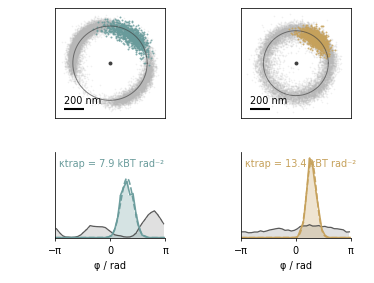

In [22]:
fig_b, axdict_b = plot_raw_diff_vs_bias_panel_b(
    m_list=m_list,
    study_particle=16,
    reference_particle=27,#126, #1, 10, 19, 22, 27, 28, 40, 42, 44, 56, 69, 70, 74, 85, 93, 103, 112, 115, 122, 129, 137, 139, 144, 150, 157, 176, 179, 180, 197, 199, 201, 213, 223
    diff_phase="diff",
    bias_phase="deg-220",

    width_mm=95,
    height_mm=72,
    fontsize=7,

    dt_s=0.005,
    px_per_nm=1.0,
    scalebar_nm=200,

    nbins=36,

    diff_marker_size=1.4,
    bias_marker_size=1.9,
    diff_alpha=0.20,
    bias_alpha=0.82,

    fixed_scatter_box=True,
    scatter_box_px=None,

    fit_gaussian_for="both",
    rasterize_locs=True,
)

plt.show()

svg_path, png_path = save_figure_svg_png(
    fig=fig_b,
    directory=r"R:\_06_Umbrella_Sampling\02_Figures\Figure_2",
    name="L2ss-fov01_Fig2_locs_rotorunderstudy_reference",
)